In [1]:
# DATA MINING 1

from yellowbrick.cluster import SilhouetteVisualizer
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans, OPTICS, cluster_optics_dbscan
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns
import plotly.express as px
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '12'

# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE
#scaling, normalization
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#kmeans, dbscan, hierarchical (sklearn)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
#evaluation
from sklearn.metrics import silhouette_score
#import dataset

#distance matrix (dbscan elbow, hierarchical)
from scipy.spatial.distance import pdist, squareform

# hierarchical (scipy)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans, OPTICS, cluster_optics_dbscan
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns
import plotly.express as px
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '12'

# Stile generale per i grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# CARICAMENTO DATAFRAME
df = pd.read_csv("/Users/ale/Documents/primo anno/dm1_25_26_dataset/df/DM1_game_dataset.csv")


In [2]:

# -----------------------------------------------
# -----------------------------------------------
# PULIZIA BASE E DEFINIZIONE GRUPPI DI COLONNE

print(f"\n----PULIZIA----")

df_cleaned = df.copy()
# Dropping delle variabili inutili
df_cleaned = df_cleaned.drop(["ComWeight", "LanguageEase", "BestPlayers", "GoodPlayers",
                              "ComMaxPlaytime", "NumComments", "ImagePath"], axis=1)

# Filtro dei valori errati = 0 non imputabili
df_cleaned = df_cleaned[df_cleaned["YearPublished"] != 0]
df_cleaned = df_cleaned[df_cleaned["MinPlayers"] != 0]
df_cleaned = df_cleaned[df_cleaned["MaxPlayers"] != 0]

# Gestione NA di Family
df_cleaned["Family"] = df_cleaned["Family"].fillna("No_Family")

# Missing values di Gameweight e ComAgeRec
df_cleaned["GameWeight"] = df_cleaned["GameWeight"].replace(0, np.nan)
df_cleaned["ComAgeRec"] = df_cleaned["ComAgeRec"].replace(np.nan, 0)


# IDEA CHIAVE: alla fine non abbiamo basi che ci permettono di rimuovere gli outliers tipo catan o Monopoli
# Però, possiamo pensare a year_published

# Colonna "Period"
condizione = [
    (df_cleaned['YearPublished'] < 1000),
    (df_cleaned['YearPublished'] >= 1000) & (
        df_cleaned['YearPublished'] < 1900),
    (df_cleaned['YearPublished'] >= 1900) & (
        df_cleaned['YearPublished'] < 2000),
    (df_cleaned['YearPublished'] >= 2000) & (
        df_cleaned['YearPublished'] < 2010),
    (df_cleaned['YearPublished'] >= 2010)
]
epoca = [
    'Pre_1000',
    '1000_1900',
    '1900_2000',
    '2000_2010',
    "2010_2021"
]
df_cleaned['Period'] = np.select(condizione, epoca, default=None)

# Colonna "Age"
df_cleaned['Age'] = 2025 - df_cleaned["YearPublished"]

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]

# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns
colonne_quanti = colonne_quanti.drop([
    "BGGId"] + colonne_binarie
    + colonne_rank + colonne_cat)

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist() +
    colonne_rank +
    colonne_cat +
    colonne_binarie
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))


# Creazione train_set e test_set per Data Leakage
train_set, test_set = train_test_split(
    df_cleaned, test_size=0.2, random_state=222)
train_set = train_set.copy()
test_set = test_set.copy()
print(f"\nDimensioni Train Set: {train_set.shape}")
print(f"\nDimensioni Test Set: {test_set.shape}")





----PULIZIA----

Dimensioni Train Set: (17251, 41)

Dimensioni Test Set: (4313, 41)


In [3]:

# -----------------------------------------------
# -----------------------------------------------
# OUTLIERS

print(f"\n----OUTLIERS MODA----")

# Gestione missing con moda
mode_mfg_playtime = train_set["MfgPlaytime"].mode()[0]
train_set["MfgPlaytime"] = train_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)
test_set["MfgPlaytime"] = test_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)

mode_com_playtime = train_set["ComMinPlaytime"].mode()[0]
train_set["ComMinPlaytime"] = train_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)
test_set["ComMinPlaytime"] = test_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)

# IMPUTAZIONE RANDOM FOREST
# Non c'è bisogno di scalare perchè gode di Invarianza Monotona

print(f"\n----OUTLIERS RANDOM FOREST----")

rf_estimator = RandomForestRegressor(
    n_estimators=22,
    random_state=222,
    n_jobs=-1
)

imputer_rf = IterativeImputer(
    estimator=rf_estimator,
    max_iter=10,
    random_state=222,
    verbose=2,               # 0 = silente, 1 = output, 2 = output dettagliato
    initial_strategy='median',
    add_indicator=False
)

df_numeric_to_impute = df_cleaned[colonne_numeriche].copy()
df_numeric_to_impute = df_numeric_to_impute.drop(["ComAgeRec"], axis=1)

imputer_rf.fit(train_set[colonne_numeriche])
imputed_array_train = imputer_rf.transform(train_set[colonne_numeriche])
imputed_array_test = imputer_rf.transform(test_set[colonne_numeriche])

train_imputed = train_set.copy()
test_imputed = test_set.copy()

train_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_train,
    columns=colonne_numeriche,
    index=train_imputed.index
)
test_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_test,
    columns=colonne_numeriche,
    index=test_imputed.index
)





----OUTLIERS MODA----

----OUTLIERS RANDOM FOREST----
[IterativeImputer] Completing matrix with shape (17251, 35)
[IterativeImputer] Ending imputation round 1/10, elapsed time 6.54
[IterativeImputer] Change: 1.584527272727272, scaled tolerance: 166.497 
[IterativeImputer] Early stopping criterion reached.
[IterativeImputer] Completing matrix with shape (17251, 35)
[IterativeImputer] Ending imputation round 1/1, elapsed time 0.02
[IterativeImputer] Completing matrix with shape (4313, 35)
[IterativeImputer] Ending imputation round 1/1, elapsed time 0.01


In [4]:

# -----------------------------------------------
# -----------------------------------------------
# TRASFORMAZIONE VARIABILI (SKEWNESS)

print(f"\n----TRASFORMAZIONE----")


def fit_trasformatore(dataframe: pd.DataFrame, colonne: list, soglia: float = 1.0):

    skew_values = dataframe[colonne].skew()
    colonne_da_trasformare = skew_values[abs(skew_values) > soglia].index

    col_log = []
    col_cbrt = []

    for col in colonne_da_trasformare:
        if dataframe[col].isnull().any():
            print(f"\n  - ATTENZIONE: '{col}' contiene NaN, non dovrebbe.")
            continue

        if dataframe[col].min() < 0:
            col_cbrt.append(col)
        else:
            col_log.append(col)

    if col_log:
        print(f"\n  - Trasformazione Logaritmica identificata per: {col_log}")
    if col_cbrt:
        print(
            f"\n  - Trasformazione Radice Cubica identificata per: {col_cbrt}")

    return col_log, col_cbrt


def apply_trasformatore(dataframe: pd.DataFrame, col_log: list, col_cbrt: list):
    df_copy = dataframe.copy()

    for col in col_log:
        if col in df_copy.columns:
            df_copy[col] = np.log1p(df_copy[col])

    for col in col_cbrt:
        if col in df_copy.columns:
            df_copy[col] = np.cbrt(df_copy[col])

    return df_copy


colonne_log, colonne_cbrt = fit_trasformatore(
    train_imputed, colonne_quanti.tolist())

train_transformed = apply_trasformatore(
    train_imputed, colonne_log, colonne_cbrt)
test_transformed = apply_trasformatore(test_imputed, colonne_log, colonne_cbrt)





----TRASFORMAZIONE----

  - Trasformazione Logaritmica identificata per: ['MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumWish', 'NumWeightVotes', 'MfgPlaytime', 'ComMinPlaytime', 'NumUserRatings', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'Age']

  - Trasformazione Radice Cubica identificata per: ['YearPublished']


In [6]:

# -----------------------------------------------
# -----------------------------------------------
# CLUSTERING

print("\n----CLUSTERING----")

X = train_transformed[colonne_numeriche]
y = np.array(train_transformed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)

# -----------------------------------------------
# K-means
print("\n----CLUSTERING (K-Means)----")

kmeans = KMeans(n_clusters=5, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

# -----------------------------------------------
# Bisecting K-means
print("\n----CLUSTERING (Bisecting K-Means)----")

bkmeans = BisectingKMeans(n_clusters=5, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

# -----------------------------------------------
# DBscan
print("\n----CLUSTERING (DBscan)----")

dbscan = DBSCAN(eps=0.01, min_samples=10)
dbscan.fit(X_minmax)

# -----------------------------------------------
# Optics
print("\n----CLUSTERING (Optics)----")

# giocare con samples e cluster size
optics = OPTICS(min_samples=20, max_eps=np.inf, min_cluster_size=10)
optics.fit(X_minmax)

# -----------------------------------------------
# Gerarchico
print("\n----CLUSTERING (Gerarchico)----")


def get_linkage_matrix(model):
    # Create linkage matrix

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix


def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)


model = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                # giocare con tipo distanza e tipo di link
                                metric='euclidean', linkage='complete')
model = model.fit(X_minmax)




----CLUSTERING----

----CLUSTERING (K-Means)----

----CLUSTERING (Bisecting K-Means)----

----CLUSTERING (DBscan)----

----CLUSTERING (Optics)----

----CLUSTERING (Gerarchico)----


In [5]:
# -----------------------------------------------
# -----------------------------------------------
# CORRELAZIONE

print("\n----CORRELAZIONE----")

# NON Trasformati
df_numeric_imputed = train_imputed.drop(
    ["BGGId", "Name", "Description", "Family", "Rating", "Period"], axis=1)

M_Cor_imputed = df_numeric_imputed.corr()

# Trasformati
df_numeric_transformed = train_transformed.drop(
    ["BGGId", "Name", "Description", "Family", "Rating", "Period"], axis=1)

M_Cor_transformed = df_numeric_transformed.corr()


# Finire pulizia                                        FATTO
# Scegliere variabili su cui fare clustering            DAFARE
# Giocare coi parametri di clustering                   DAFARE



train_cluster = train_imputed.copy()
test_cluster = test_imputed.copy()
colonne_cluster = ["MinPlayers", "GameWeight", "MfgAgeRec", "NumWant", "NumUserRatings", "NumImplementations"]
train_cluster = train_cluster[colonne_cluster]
test_cluster = test_cluster[colonne_cluster]

X = train_cluster
y = np.array(train_imputed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=5, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)




----CORRELAZIONE----


KMeans(max_iter=100, n_clusters=5, n_init=10, random_state=222)

In [6]:
#PCA
scalerStan = StandardScaler()
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = scaler.fit_transform(features)
pca = PCA(n_components=2, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2'])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)
    
print("\n--- Varianza Spiegata ---")
print(f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(f"Varianza Totale Spiegata (2 componenti): {total_explained_variance:.4f} ({total_explained_variance*100:.2f}%)")


--- Varianza Spiegata ---
Varianza spiegata da PC1: 0.5849 (58.49%)
Varianza spiegata da PC2: 0.2816 (28.16%)
Varianza Totale Spiegata (2 componenti): 0.8665 (86.65%)



--- Varianza Spiegata ---
Varianza spiegata da PC1: 0.5849 (58.49%)
Varianza spiegata da PC2: 0.2816 (28.16%)
Varianza Totale Spiegata (2 componenti): 1.0000 (100.00%)


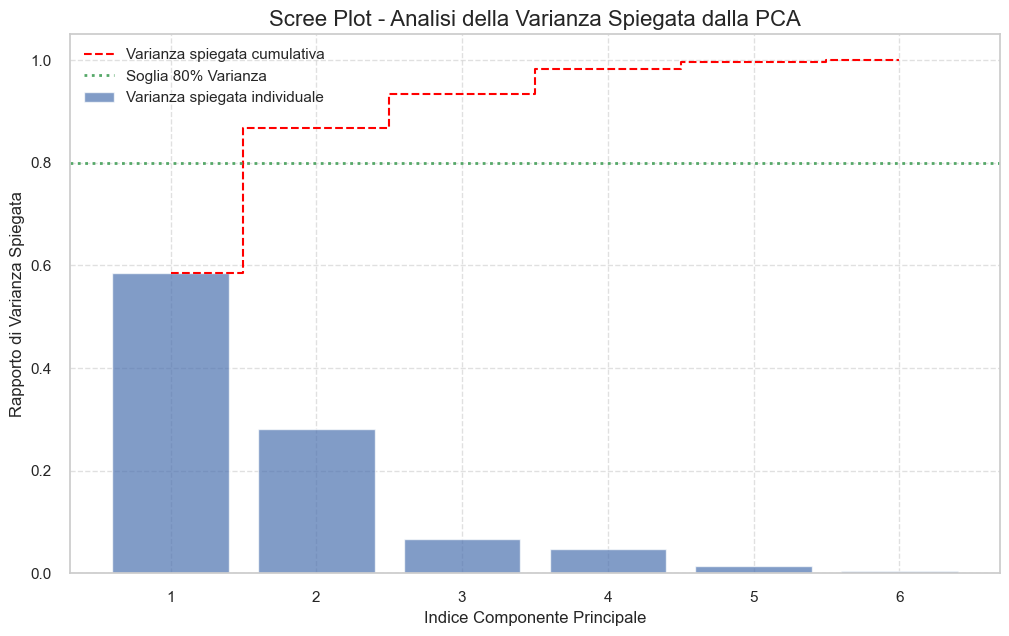


Numero di componenti necessari per spiegare almeno l'80% della varianza: 2


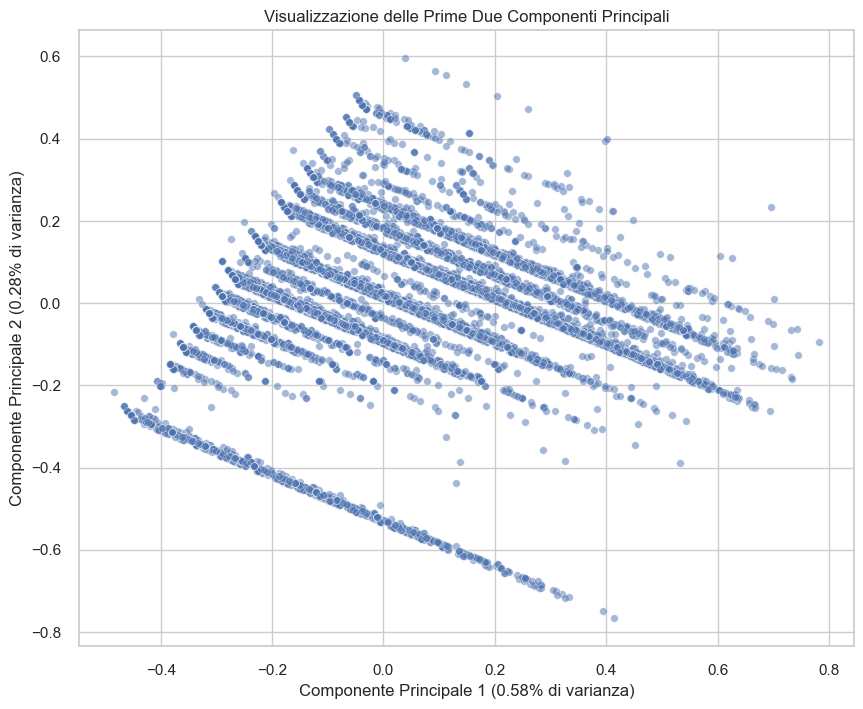

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#PCA
scalerStan = StandardScaler()
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = scaler.fit_transform(features)
pca = PCA(n_components=6, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2','PC3','PC4','PC5','PC6'])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)
    
print("\n--- Varianza Spiegata ---")
print(f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(f"Varianza Totale Spiegata (2 componenti): {total_explained_variance:.4f} ({total_explained_variance*100:.2f}%)")

# Calcoliamo la varianza spiegata individuale e quella cumulativa
varianza_spiegata_individuale = pca.explained_variance_ratio_
varianza_cumulativa = np.cumsum(varianza_spiegata_individuale)


# --- 3. CREAZIONE DELLO SCREE PLOT ---
# Ora usiamo le variabili appena calcolate per creare il grafico che hai richiesto.

plt.figure(figsize=(12, 7))

# Grafico a barre per la varianza spiegata da ogni singola componente
plt.bar(range(1, len(varianza_spiegata_individuale) + 1), varianza_spiegata_individuale, alpha=0.7, align='center',
        label='Varianza spiegata individuale')

# Grafico a linea per la varianza spiegata cumulativa
plt.step(range(1, len(varianza_cumulativa) + 1), varianza_cumulativa, where='mid',
         label='Varianza spiegata cumulativa', color='red', linestyle='--')

# Impostazioni del grafico
plt.ylabel('Rapporto di Varianza Spiegata', fontsize=12)
plt.xlabel('Indice Componente Principale', fontsize=12)
plt.title('Scree Plot - Analisi della Varianza Spiegata dalla PCA', fontsize=16)
plt.xticks(range(1, len(varianza_spiegata_individuale) + 1)) # Assicura che ci sia un tick per ogni componente
plt.grid(True, which='both', linestyle='--', alpha=0.6)

# Aggiungiamo una linea per l'80% di varianza, un target comune
plt.axhline(y=0.8, color='g', linestyle=':', linewidth=2, label='Soglia 80% Varianza')

# Mostra la legenda
plt.legend(loc='best')

# Mostra il grafico
plt.show()

# --- 4. DETERMINAZIONE DEL NUMERO OTTIMALE DI COMPONENTI (OPZIONALE) ---
# Troviamo programmaticamente il numero di componenti per spiegare almeno l'80% della varianza
try:
    n_components_80_var = np.where(varianza_cumulativa >= 0.80)[0][0] + 1
    print(f"\nNumero di componenti necessari per spiegare almeno l'80% della varianza: {n_components_80_var}")
except IndexError:
    print("\nNessun sottoinsieme di componenti raggiunge la soglia dell'80% di varianza.")


# Creiamo lo scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    alpha=0.5, # Trasparenza per vedere la densità dei punti
    s=30       # Dimensione dei punti
)

plt.title('Visualizzazione delle Prime Due Componenti Principali')
plt.xlabel(f'Componente Principale 1 ({explained_variance[0]:.2f}% di varianza)')
plt.ylabel(f'Componente Principale 2 ({explained_variance[1]:.2f}% di varianza)')
plt.grid(True)
plt.show()




--- Varianza Spiegata ---
Varianza spiegata da PC1: 0.5849 (58.49%)
Varianza spiegata da PC2: 0.2816 (28.16%)
Varianza spiegata da PC3: 0.0673 (6.73%)
Varianza Totale Spiegata (3 componenti): 0.9339 (93.39%)


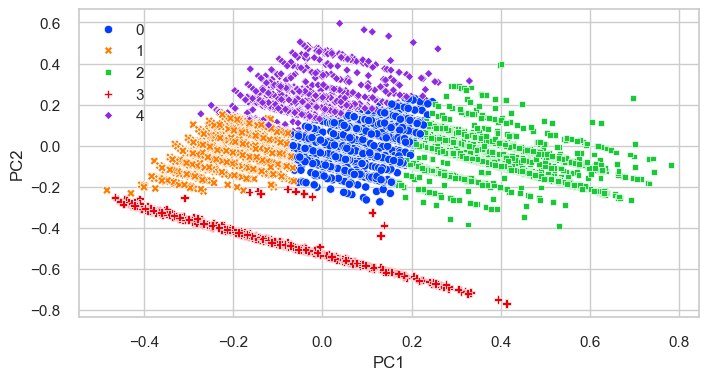

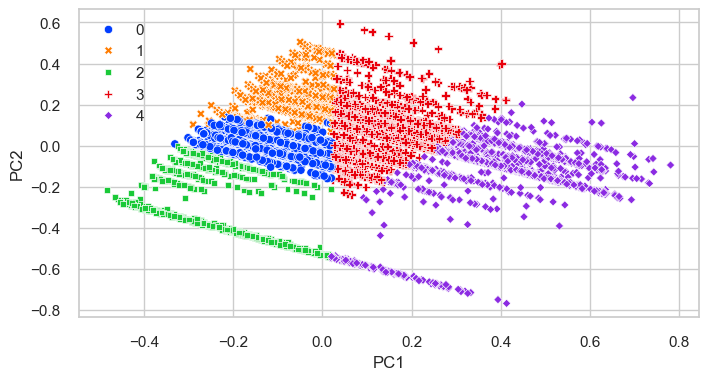

In [10]:
#Dataset_cluster
train_cluster = train_imputed.copy()
test_cluster = test_imputed.copy()
colonne_cluster = ["MinPlayers", "GameWeight", "MfgAgeRec", "NumWant", "NumUserRatings", "NumImplementations"]
train_cluster = train_cluster[colonne_cluster]
test_cluster = test_cluster[colonne_cluster]
X = train_cluster
y = np.array(train_imputed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)

#PCA
scalerStan = StandardScaler()
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = scaler.fit_transform(features)
pca = PCA(n_components=3, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2', "PC3"])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)
    
print("\n--- Varianza Spiegata ---")
print(f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(
    f"Varianza spiegata da PC3: {explained_variance[2]:.4f} ({explained_variance[2]*100:.2f}%)")
print(f"Varianza Totale Spiegata (3 componenti): {total_explained_variance:.4f} ({total_explained_variance*100:.2f}%)")

#K_Means
kmeans = KMeans(n_clusters=5, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()

#Bisecting K_Means
bkmeans = BisectingKMeans(n_clusters=5, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright")
plt.show()

452.74669416869284


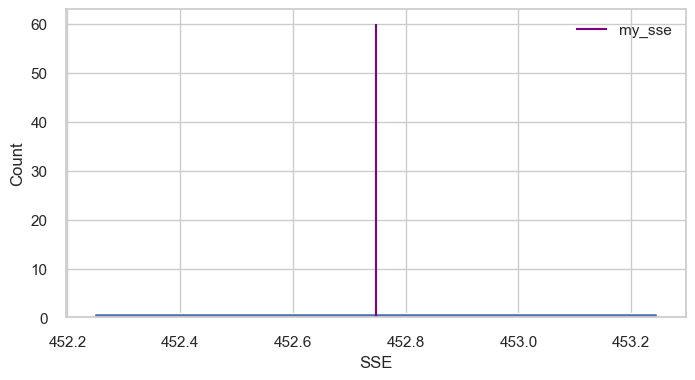

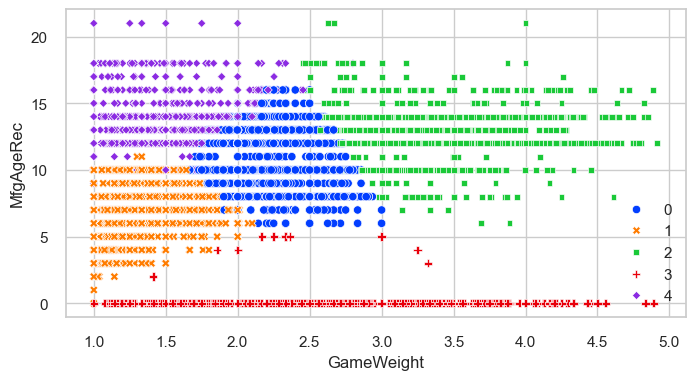

In [11]:
N = 500
sse_stats = []

for _ in range(N):
    Xi = np.zeros(shape=X_minmax.shape)

    for cidx in range(Xi.shape[1]):
        col = X_minmax[:, cidx]
        min, max, nor = np.min(col), np.max(col), len(col)
        Xi[:, cidx] = np.random.uniform(min, max, (1, nor))

    kmeans = KMeans(n_clusters=5, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)
sse_stats.append(kmeans.inertia_)
my_sse = kmeans.inertia_
print(my_sse)
plt.hist(sse_stats, bins='auto')
plt.vlines(x = my_sse, ymin = 0, ymax = 60, colors = 'purple', label = 'my_sse')
plt.xlabel('SSE')
plt.ylabel('Count')
plt.legend()
plt.show()

sns.scatterplot(data=train_cluster,
                x="GameWeight",
                y="MfgAgeRec",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()

CPU times: user 2min 51s, sys: 4min 2s, total: 6min 54s
Wall time: 39 s


<Axes: >

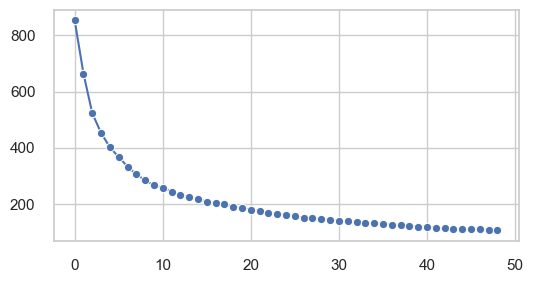

In [12]:
%%time
sse_list = []
plt.rcParams['figure.figsize'] = (6, 3)

for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state = 42)
    kmeans.fit(X_minmax)
    sse_list.append(kmeans.inertia_)
    sse_list

sse_list
sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o')

In [13]:

k=20
sse_list = []

for k in range(2, k):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state = 42)
    kmeans.fit(X_minmax)
    sse_list.append(kmeans.inertia_)


sil_list = []

for k in range(2, k):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100,random_state = 42)
    kmeans.fit(X_minmax)
    sil_list.append(silhouette_score(X_minmax, kmeans.labels_))


pdist(X_minmax).shape

squareform(pdist(X_minmax))

sil_list = []
dist = squareform(pdist(X_minmax)) # using a precomputed distance matrix

for k in range(2, k):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100)
    kmeans.fit(X_minmax)
    sil_list.append(silhouette_score(dist, kmeans.labels_, metric='precomputed'))


'''
fig, axs = plt.subplots(2)

sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o', ax=axs[0])
axs[0].set(xlabel='k', ylabel='SSE')

sns.lineplot(x=range(len(sil_list)), y=sil_list, marker='o', ax=axs[1])
axs[1].set(xlabel='k', ylabel='Silhouette')

plt.tight_layout() # Adjust the padding between and around subplots
plt.show'''


"\nfig, axs = plt.subplots(2)\n\nsns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o', ax=axs[0])\naxs[0].set(xlabel='k', ylabel='SSE')\n\nsns.lineplot(x=range(len(sil_list)), y=sil_list, marker='o', ax=axs[1])\naxs[1].set(xlabel='k', ylabel='Silhouette')\n\nplt.tight_layout() # Adjust the padding between and around subplots\nplt.show"

<function matplotlib.pyplot.show(close=None, block=None)>

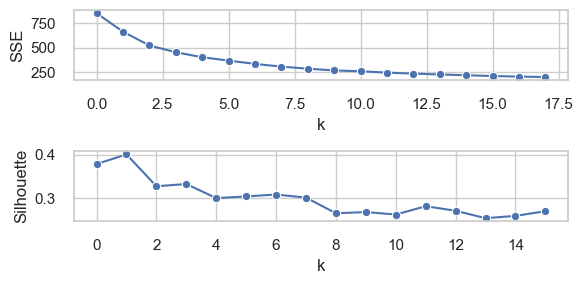

In [14]:

fig, axs = plt.subplots(2)

sns.lineplot(x=range(len(sse_list)), y=sse_list, marker='o', ax=axs[0])
axs[0].set(xlabel='k', ylabel='SSE')

sns.lineplot(x=range(len(sil_list)), y=sil_list, marker='o', ax=axs[1])
axs[1].set(xlabel='k', ylabel='Silhouette')

plt.tight_layout() # Adjust the padding between and around subplots
plt.show

In [ ]:
# Il tuo tentativo (sintassi non corretta)
# a = train_cluster[train_cluster['GameWeight','ComAgeRec']]

# Codice corretto
# Seleziona le colonne 'GameWeight' e 'ComAgeRec' e le assegna a un nuovo DataFrame.
# Ho usato un nome di variabile più descrittivo.
features_for_clustering = train_cluster[['GameWeight', 'MfgAgeRec']]

# Ora puoi usare 'features_for_clustering' per il tuo modello di clustering.
 
prova= scaler.fit_transform(features_for_clustering)

k=20
sse_list2 = []

for k in range(2, k):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state = 42)
    kmeans.fit(prova)
    sse_list2.append(kmeans.inertia_)



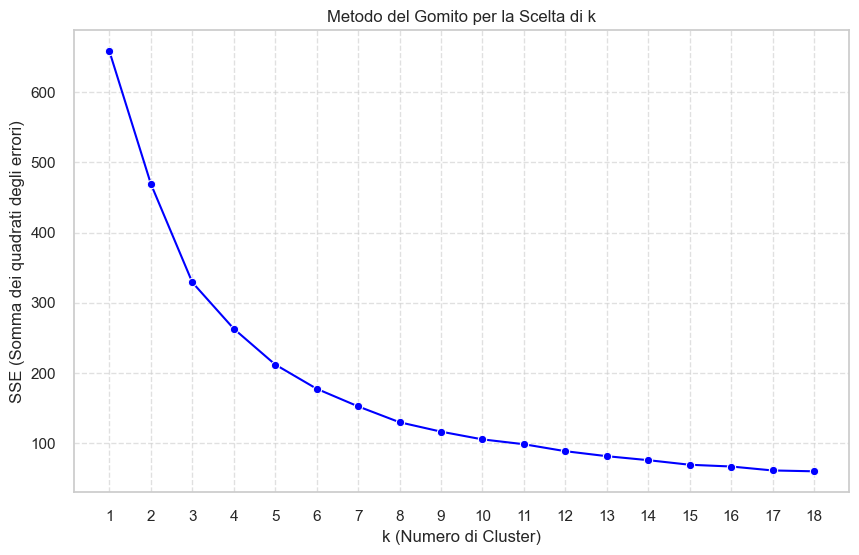

In [16]:
# --- CODICE CORRETTO PER IL GRAFICO ---

# 1. Crea una figura e un singolo subplot (chiamato 'ax' per convenzione)
fig, ax = plt.subplots(figsize=(10, 6)) # Aggiungere figsize è una buona pratica

# 2. Crea il grafico a linea sull'oggetto 'ax'
# Nota: l'asse x dovrebbe rappresentare i valori di k, non solo l'indice.
# Se k parte da 1, usiamo range(1, len(sse_list2) + 1).
k_range = range(1, len(sse_list2) + 1)
sns.lineplot(x=k_range, y=sse_list2, marker='o', ax=ax, color='blue', linestyle='-')

# 3. Imposta etichette e titolo direttamente su 'ax'
ax.set(
    xlabel='k (Numero di Cluster)',
    ylabel='SSE (Somma dei quadrati degli errori)',
    title='Metodo del Gomito per la Scelta di k'
)
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_xticks(k_range) # Assicura che tutti i valori di k siano mostrati sull'asse x

# 4. Mostra il grafico
plt.show()



--- Varianza Spiegata ---
Varianza spiegata da PC1: 0.6481 (64.81%)
Varianza spiegata da PC2: 0.2549 (25.49%)
Varianza spiegata da PC3: 0.0493 (4.93%)
Varianza spiegata da PC4: 0.0344 (3.44%)
Varianza spiegata da PC5: 0.0097 (0.97%)
Varianza spiegata da PC6: 0.0035 (0.35%)
Varianza Totale Spiegata (6 componenti): 1.0000 (100.00%)


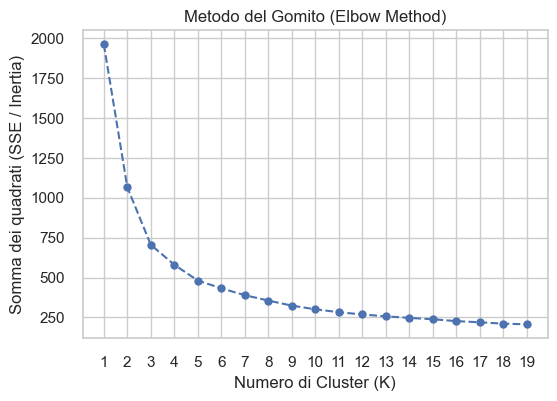

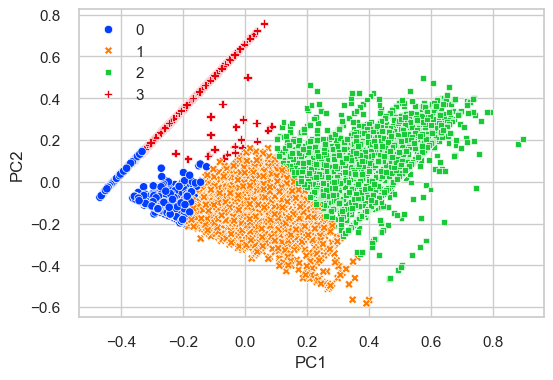

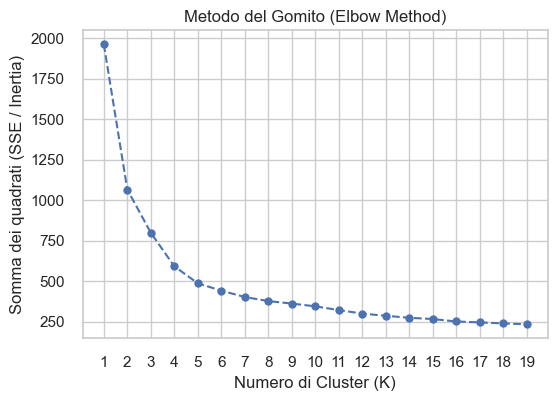

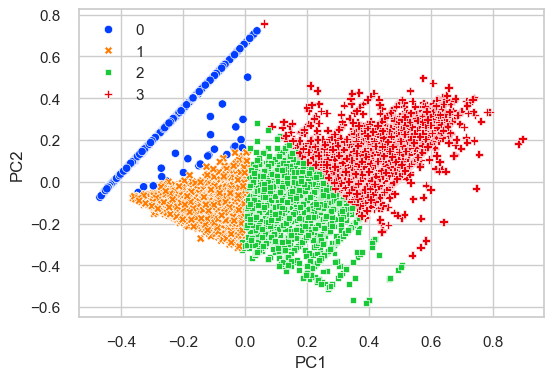

KeyError: "['MfgAgeRec'] not in index"

In [ ]:

from pyclustering.cluster import xmeans

plt.rcParams['figure.figsize'] = (6, 4)


# Dataset_cluster
train_cluster = train_imputed.copy()
test_cluster = test_imputed.copy()
colonne_cluster = ["MinPlayers", "GameWeight", "ComAgeRec",
                   "NumWant", "NumUserRatings", "NumImplementations"]
train_cluster = train_cluster[colonne_cluster]
test_cluster = test_cluster[colonne_cluster]
X = train_cluster
y = np.array(train_imputed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)

# PCA
scalerStan = StandardScaler()
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = scaler.fit_transform(features)
pca = PCA(n_components=6, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2', "PC3", "PC4", "PC5", "PC6"])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)

print("\n--- Varianza Spiegata ---")
print(
    f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(
    f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(
    f"Varianza spiegata da PC3: {explained_variance[2]:.4f} ({explained_variance[2]*100:.2f}%)")
print(
    f"Varianza spiegata da PC4: {explained_variance[3]:.4f} ({explained_variance[3]*100:.2f}%)")

print(
    f"Varianza spiegata da PC5: {explained_variance[4]:.4f} ({explained_variance[4]*100:.2f}%)")

print(
    f"Varianza spiegata da PC6: {explained_variance[5]:.4f} ({explained_variance[5]*100:.2f}%)")

print(
    f"Varianza Totale Spiegata (6 componenti): {total_explained_variance:.4f} ({total_explained_variance*100:.2f}%)")



# K_Means
sse = []
k_range = range(1, 20)

for k in k_range:

    kmeans_model = KMeans(n_clusters=k,
                          n_init=10,
                          max_iter=100,
                          random_state=222)

    kmeans_model.fit(X_minmax)

    sse.append(kmeans_model.inertia_)

plt.plot(k_range, sse, marker='o', linestyle='--')
plt.xlabel("Numero di Cluster (K)")
plt.ylabel("Somma dei quadrati (SSE / Inertia)")
plt.title("Metodo del Gomito (Elbow Method)")
plt.xticks(k_range)
plt.grid(True)
plt.show()


kmeans = KMeans(n_clusters=4, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()



# Bisecting K_Means
sse = []
k_range = range(1, 20)

for k in k_range:

    bkmeans_model = BisectingKMeans(n_clusters=k,
                          n_init=10,
                          max_iter=100,
                          random_state=222)

    bkmeans_model.fit(X_minmax)

    sse.append(bkmeans_model.inertia_)

plt.plot(k_range, sse, marker='o', linestyle='--')
plt.xlabel("Numero di Cluster (K)")
plt.ylabel("Somma dei quadrati (SSE / Inertia)")
plt.title("Metodo del Gomito (Elbow Method)")
plt.xticks(k_range)
plt.grid(True)
plt.show()


bkmeans = BisectingKMeans(n_clusters=4, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright")
plt.show()



#X_Means
K_MAX = 20
xmeans_instance = xmeans.xmeans(data=pca_df,
                         kmax=K_MAX,
                         random_state=222)

xmeans_instance.process()
clusters = xmeans_instance.get_clusters()
n_clusters_found = len(clusters)
labels_xmeans = np.zeros(len(X_minmax), dtype=int)
for cluster_id, points_in_cluster in enumerate(clusters):
    for point_index in points_in_cluster:
        labels_xmeans[point_index] = cluster_id

plt.figure(figsize=(8, 6))  # Puoi regolare la dimensione
sns.scatterplot(data=pca_df,
                x="GameWeight",
                y="MfgAgeRec",
                hue=labels_xmeans,
                style=labels_xmeans,
                # Adatta la palette al K trovato
                palette=sns.color_palette("bright", n_colors=n_clusters_found))
plt.title(f'X-Means Clustering (K={n_clusters_found} trovato)')
plt.show()

In [27]:
# -----------------------------------------------
# X-means
from pyclustering.cluster import xmeans
X =pca_df

xm = xmeans.xmeans(X)
xm.process()
clusters = xm.get_clusters()

def clusters_to_labels(clusters):
    labels = np.empty(shape=(len(np.concatenate(clusters))), dtype=int)
    for i in range(len(clusters)):
        for idx in clusters[i]:
            labels[idx] = i
    return labels

labels = clusters_to_labels(clusters)
centers = np.array(xm.get_centers())
centers_unscaled = scaler.inverse_transform(centers)

sns.scatterplot(data=train_transformed, x="PC1",
                y="PC2", hue=labels, palette="bright", style=labels)
plt.scatter(centers_unscaled[:, 0], centers_unscaled[:,7], color="black", marker="*", s=100)
plt.show()

scaler = StandardScaler()
X = scaler.fit_transform(train_transformed[['PC1', 'PC2']]) # Usiamo solo le due feature per il plot




ValueError: operands could not be broadcast together with shapes (20,6) (2,) (20,6) 

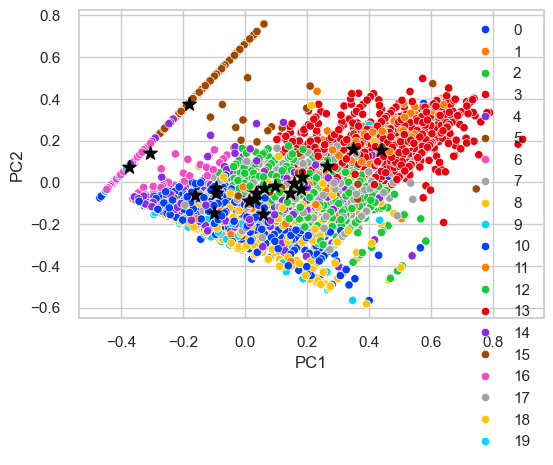

In [31]:
scaler = StandardScaler()
X = scaler.fit_transform(pca_df)

xm = xmeans.xmeans(X)
xm.process()
clusters = xm.get_clusters()
labels = clusters_to_labels(clusters)
centers = np.array(xm.get_centers())
centers_unscaled = scaler.inverse_transform(centers)

sns.scatterplot(data=pca_df,
    x='PC1',
    y='PC2',
    hue=labels, palette="bright"
)
plt.scatter(
    centers_unscaled[:, 0],
    centers_unscaled[:, 1],
    color="black", marker="*", s=100
)
plt.show()

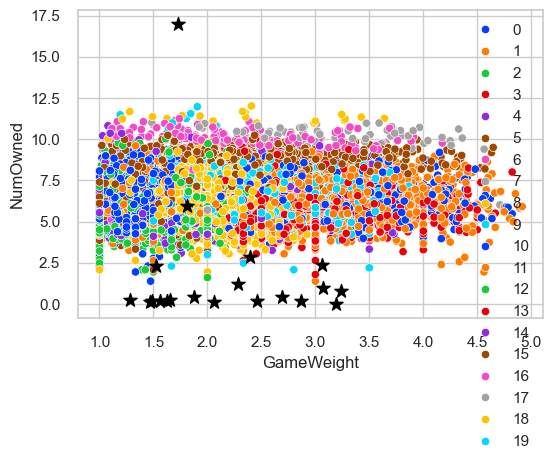

In [34]:
# 1. Scala tutte le colonne numeriche
scaler = StandardScaler()
X = scaler.fit_transform(train_cluster)

# 2. Esegui X-means
xm = xmeans.xmeans(X)
xm.process()
clusters = xm.get_clusters()
labels = clusters_to_labels(clusters)
centers = np.array(xm.get_centers())

# 3. Riporta i centroidi nello spazio originale
centers_unscaled = scaler.inverse_transform(centers)

# 4. Plot usando due feature a scelta
sns.scatterplot(
    data=train_transformed,
    x="GameWeight",
    y="NumOwned",
    hue=labels,
    palette="bright"
)
# trova gli indici corretti di GameWeight e NumOwned
idx_x = colonne_numeriche.index("GameWeight")
idx_y = colonne_numeriche.index("NumOwned")

plt.scatter(
    centers_unscaled[:, idx_x],
    centers_unscaled[:, idx_y],
    color="black", marker="*", s=100
)
plt.show()

In [1]:
from pyclustering.cluster import xmeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import NearestNeighbors


plt.rcParams['figure.figsize'] = (6, 4)

# Dataset_cluster
train_cluster = train_imputed.copy()
test_cluster = test_imputed.copy()
colonne_cluster = ["MinPlayers", "GameWeight", "ComAgeRec",
                   "NumWant", "NumUserRatings", "NumImplementations"]
train_cluster = train_cluster[colonne_cluster]
test_cluster = test_cluster[colonne_cluster]
X = train_cluster
y = np.array(train_imputed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)
standard_scaler = StandardScaler()
X_standard = standard_scaler.fit_transform(X)

# PCA
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = scaler.fit_transform(features)
pca = PCA(n_components=6, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2', "PC3", "PC4", "PC5", "PC6"])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)

print("\n--- Varianza Spiegata ---")
print(
    f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(
    f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(
    f"Varianza spiegata da PC3: {explained_variance[2]:.4f} ({explained_variance[2]*100:.2f}%)")
print(
    f"Varianza spiegata da PC4: {explained_variance[3]:.4f} ({explained_variance[3]*100:.2f}%)")

print(
    f"Varianza spiegata da PC5: {explained_variance[4]:.4f} ({explained_variance[4]*100:.2f}%)")

print(
    f"Varianza spiegata da PC6: {explained_variance[5]:.4f} ({explained_variance[5]*100:.2f}%)")

print(
    f"Varianza Totale Spiegata (6 componenti): {total_explained_variance:.4f} ({total_explained_variance*100:.2f}%)")

# K_Means
sse = []
k_range = range(1, 20)

for k in k_range:

    kmeans_model = KMeans(n_clusters=k,
                          n_init=10,
                          max_iter=100,
                          random_state=222)

    kmeans_model.fit(X_minmax)

    sse.append(kmeans_model.inertia_)

plt.plot(k_range, sse, marker='o', linestyle='--')
plt.xlabel("Numero di Cluster (K)")
plt.ylabel("Somma dei quadrati (SSE / Inertia)")
plt.title("Metodo del Gomito (Elbow Method)")
plt.xticks(k_range)
plt.grid(True)
plt.show()

kmeans = KMeans(n_clusters=4, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

centers = kmeans.cluster_centers_
centers_unscaled = scaler.inverse_transform(centers)

sns.scatterplot(data=train_cluster,
                x="GameWeight",
                y="ComAgeRec",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.scatter(
    centers_unscaled[:, 1],
    centers_unscaled[:, 2],
    color="black", marker="*", s=100
)
plt.show()

# Bisecting K_Means
sse = []
k_range = range(1, 20)

for k in k_range:

    bkmeans_model = BisectingKMeans(n_clusters=k,
                                    n_init=10,
                                    max_iter=100,
                                    random_state=222)

    bkmeans_model.fit(X_minmax)

    sse.append(bkmeans_model.inertia_)

plt.plot(k_range, sse, marker='o', linestyle='--')
plt.xlabel("Numero di Cluster (K)")
plt.ylabel("Somma dei quadrati (SSE / Inertia)")
plt.title("Metodo del Gomito (Elbow Method)")
plt.xticks(k_range)
plt.grid(True)
plt.show()

bkmeans = BisectingKMeans(n_clusters=4, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright")
plt.show()


# DBScan

D = X_minmax.shape[1]
MinPts = 2 * D
k = MinPts

nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_minmax)
distances, indices = nn.kneighbors(X_minmax)

k_distances = distances[:, k-1]
k_distances_sorted = np.sort(k_distances)
plt.plot(range(len(k_distances_sorted)), k_distances_sorted)
plt.title(f'Grafico K-distance (k = {k}) per DBSCAN')
plt.xlabel('Indice dei punti (ordinati per distanza)')
plt.ylabel(f'Distanza dal {k}-esimo vicino (Epsilon)')
plt.grid(True)
print("Mostro il k-distance plot...")
plt.show()


dbscan = DBSCAN(eps=0.01, min_samples=100)
dbscan.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=dbscan.labels_,
                style=dbscan.labels_,
                palette="bright")
plt.show()

'''
###ATTENZIONE: PESANTE
dist = pdist(X_minmax, 'euclidean')
dist = squareform(dist)
sns.heatmap(dist, cmap="Greens_r", annot=False)
plt.show()

k = 6
kth_distances = []

for d in dist:  # d is a vector containing distances between the ith record and all the others
    # take the index of the kth nearest neighbor
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])  # store the distance in a list


plt.plot(range(0, len(kth_distances)), sorted(kth_distances))
plt.ylabel('distance from the {}th neighbor'.format(k))

plt.show()
ks = [16]

fig_dims = (1, len(ks))

for i in range(len(ks)):
    k = ks[i]
    kth_distances = []

    for d in dist:  # d is a vector containing distances between the ith record and all the others
        # take the index of the kth nearest neighbor
        index_kth_distance = np.argsort(d)[k]
        # store the distance in a list
        kth_distances.append(d[index_kth_distance])

    plt.subplot2grid(fig_dims, (0, i))
    plt.plot(range(0, len(kth_distances)), sorted(kth_distances))
    plt.ylabel('distance from the {}th neighbor'.format(k))

plt.tight_layout()
plt.show()
'''

#TROPPO PESANTE
'''
# Creiamo le griglie per gli assi X e Y
# X = indice del punto (da 0 a num_points)
# Y = valore di k
X_grid, Y_grid = np.meshgrid(range(num_points), ks)

# Z = matrice vuota per le distanze (asse Z)
Z_grid = np.zeros_like(X_grid, dtype=float)

# Calcoliamo la griglia Z
print("Calcolo delle distanze k-nn...")
for i, k in enumerate(ks):
    kth_distances = []
    for d in dist:  # d è un vettore di distanze
        # Prende l'indice del k-esimo vicino più vicino
        index_kth_distance = np.argsort(d)[k]
        # Salva la distanza
        kth_distances.append(d[index_kth_distance])
    
    # Inseriamo le distanze ordinate nella riga appropriata della griglia Z
    Z_grid[i, :] = sorted(kth_distances)

print("Creazione del grafico 3D...")

# --- Creazione del Grafico 3D ---
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Disegniamo la superficie
surf = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap='viridis', edgecolor='none')

# Impostiamo le etichette
ax.set_title('Superficie 3D delle distanze k-NN')
ax.set_xlabel('Indice del punto (ordinato per distanza)')
ax.set_ylabel('k (Numero vicino)')
ax.set_zlabel('Distanza dal k-esimo vicino')

# Aggiungiamo una colorbar
fig.colorbar(surf, shrink=0.5, aspect=5)

plt.tight_layout()
plt.show()'''

NameError: name 'plt' is not defined